# Fashion-MNIST Classification: One CNN Architecture Across Three Implementations

This notebook develops a convolutional neural network designed to categorize grayscale clothing images into ten distinct fashion item classes: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, and Ankle boot. The underlying learning problem remains fixed throughout, and the identical convolutional architecture is constructed across three separate implementation paradigms:

1. **NumPy from scratch**: Every mathematical operation (2D convolutions, max pooling, rectified linear activations, fully connected projections, softmax cross-entropy, backward gradient backpropagation, and stochastic parameter updates) is implemented using raw array operations with zero dependencies on deep learning libraries.
2. **TensorFlow and Keras**: The architecture is specified using high-level declarative layers, delegating automatic differentiation, computational graph optimization, and runtime execution to the backend C++ engine.
3. **PyTorch**: The network is constructed as an object-oriented `nn.Module`, combining concise modular layer abstractions with an explicit, imperative training and optimization loop.

The primary objective is evaluating how abstraction levels alter development transparency, implementation effort, and execution efficiency when the underlying neural network architecture and mathematical formulation are strictly held constant.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)
import json
import os

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

sns.set_theme(style="whitegrid")

In [2]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
import random
random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

## Loading the Dataset

The Fashion-MNIST dataset is imported using Keras's built-in dataset utility, eliminating the need for external file downloads or custom unpacking scripts. The resulting training and testing arrays are loaded into memory and reused across all three implementations. Consequently, each model processes the exact same training instances in identical sequence and is evaluated against the same test partition.

In [3]:
(X_train_raw, y_train), (X_test_raw, y_test) = keras.datasets.fashion_mnist.load_data()

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

print("Train:", X_train_raw.shape, y_train.shape)
print("Test:", X_test_raw.shape, y_test.shape)
print("Pixel range before normalization:", X_train_raw.min(), "to", X_train_raw.max())

Train: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)
Pixel range before normalization: 0 to 255


## Exploratory Data Understanding

Prior to assembling the neural architecture, exploratory inspection is performed on the raw data: verifying class distribution balance, viewing authentic visual samples, and checking pixel intensity distributions across the clothing items.

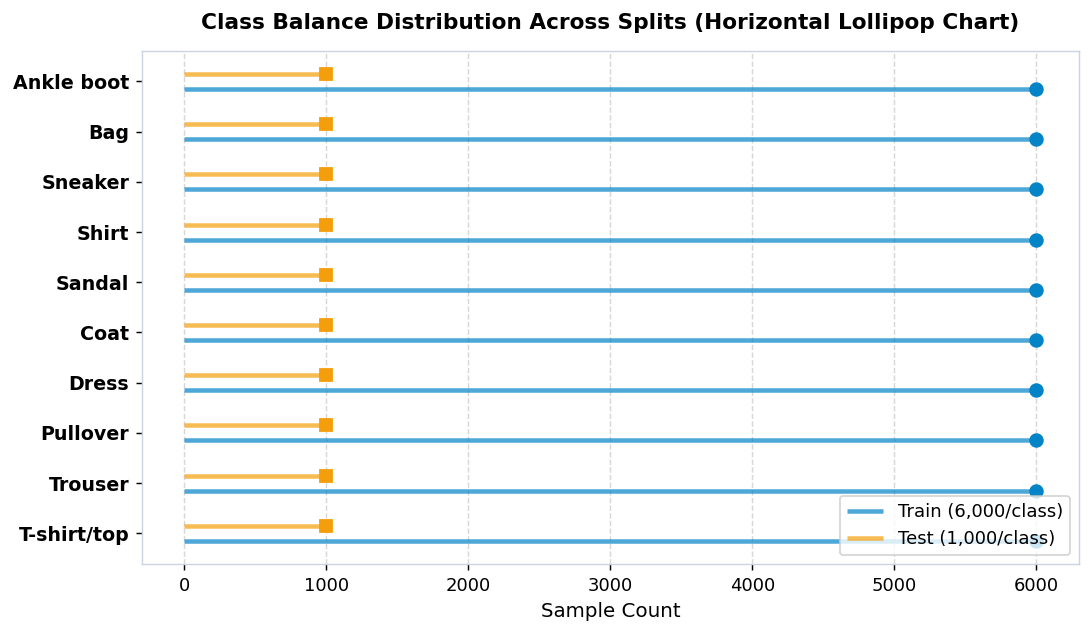

In [4]:
# Class balance distribution across splits using a horizontal lollipop chart
train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)
y_indices = np.arange(10)

plt.figure(figsize=(8.5, 5))
plt.hlines(y=y_indices - 0.15, xmin=0, xmax=train_counts, color="#0284C7", linewidth=2.5, alpha=0.7, label="Train (6,000/class)")
plt.plot(train_counts, y_indices - 0.15, "o", color="#0284C7", markersize=7)

plt.hlines(y=y_indices + 0.15, xmin=0, xmax=test_counts, color="#F59E0B", linewidth=2.5, alpha=0.7, label="Test (1,000/class)")
plt.plot(test_counts, y_indices + 0.15, "s", color="#F59E0B", markersize=7)

plt.yticks(y_indices, CLASS_NAMES, fontsize=10.5)
plt.xlabel("Sample Count")
plt.title("Class Balance Distribution Across Splits", fontsize=12, pad=12)
plt.legend(loc="lower right", frameon=True)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


Every category contains precisely 6,000 training examples and 1,000 evaluation instances. The dataset is perfectly balanced across all ten target classes, meaning no loss reweighting or synthetic sample adjustment is necessary: a baseline classifier predicting a single arbitrary class would achieve exactly 10.0% test accuracy.

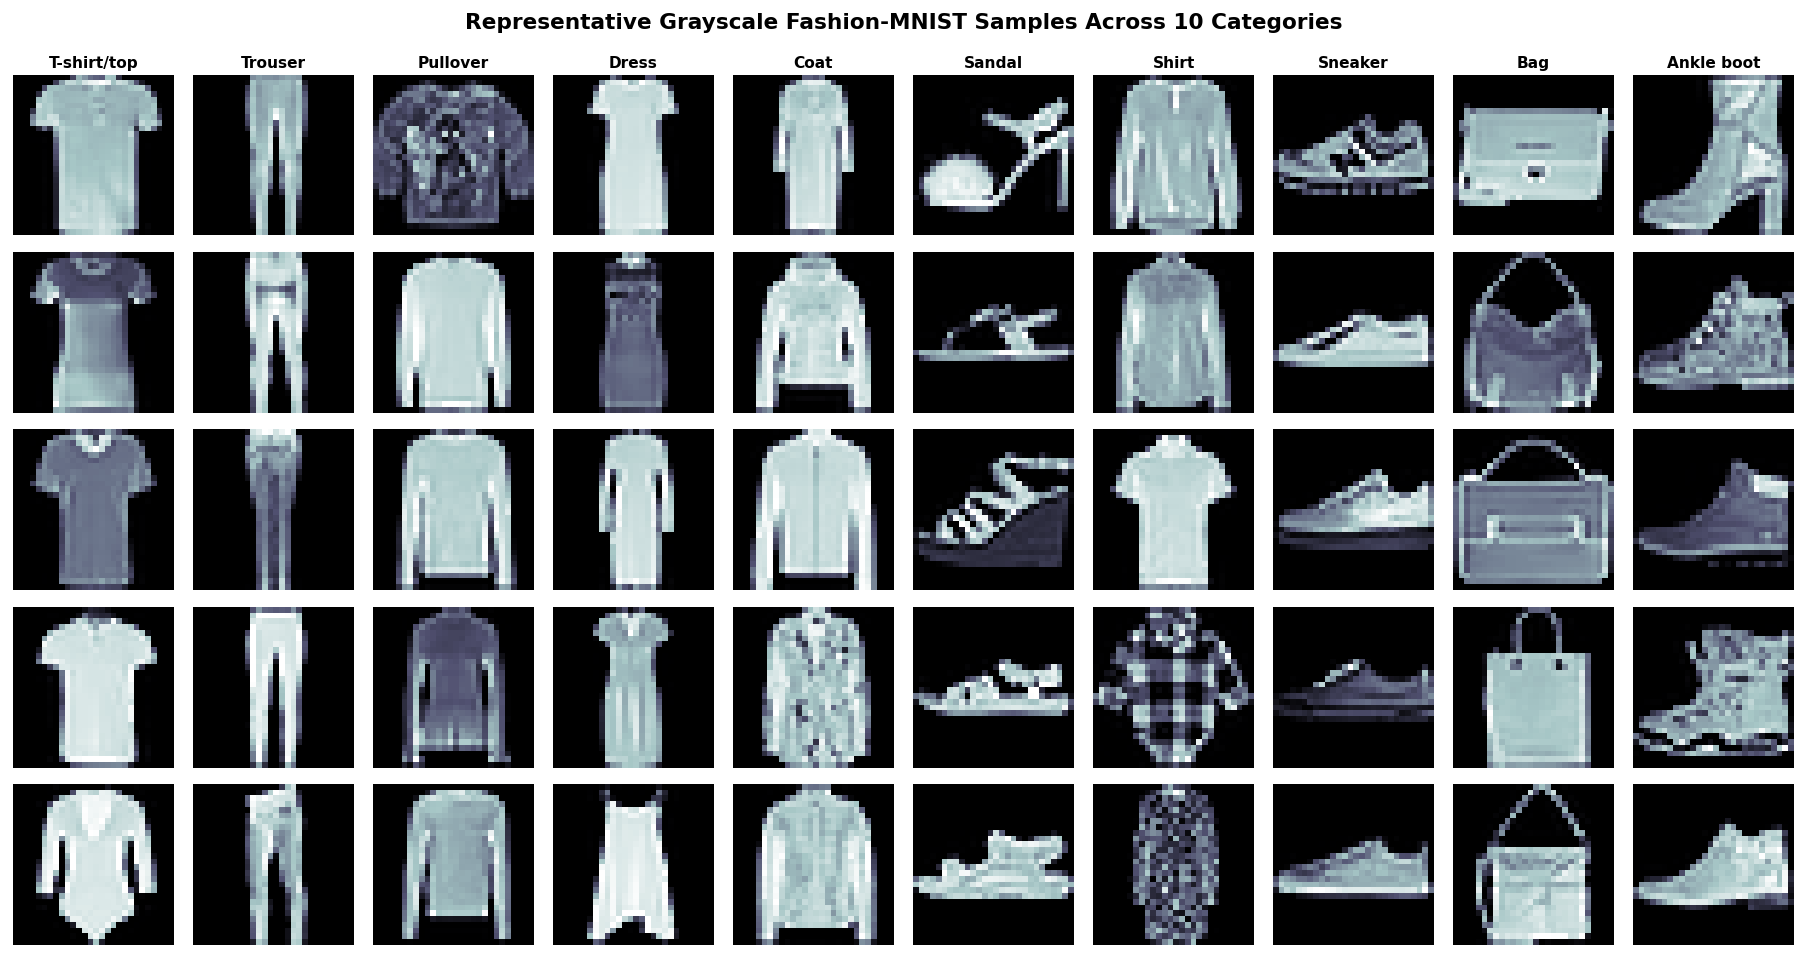

In [5]:
# Visualizing representative dataset samples across all 10 fashion classes
fig, axes = plt.subplots(5, 10, figsize=(14, 7.5))
rng = np.random.default_rng(RANDOM_SEED)

for class_idx in range(10):
    class_examples = np.where(y_train == class_idx)[0]
    chosen = rng.choice(class_examples, size=5, replace=False)
    for row, example_idx in enumerate(chosen):
        ax = axes[row, class_idx]
        ax.imshow(X_train_raw[example_idx], cmap="bone")
        ax.axis("off")
        if row == 0:
            ax.set_title(CLASS_NAMES[class_idx], fontsize=8.5, weight="bold", pad=4)

plt.suptitle("Representative Grayscale Fashion-MNIST Samples", fontsize=12, y=0.98)
plt.tight_layout()
plt.show()


While macro-categories are readily distinguishable (for example, a sandal possesses little geometric resemblance to a trouser), specific clothing categories exhibit substantial visual ambiguity. In particular, distinguishing between shirts, t-shirts, coats, and pullovers presents subtle silhouette differences that can challenge both human observers and automated feature extractors.

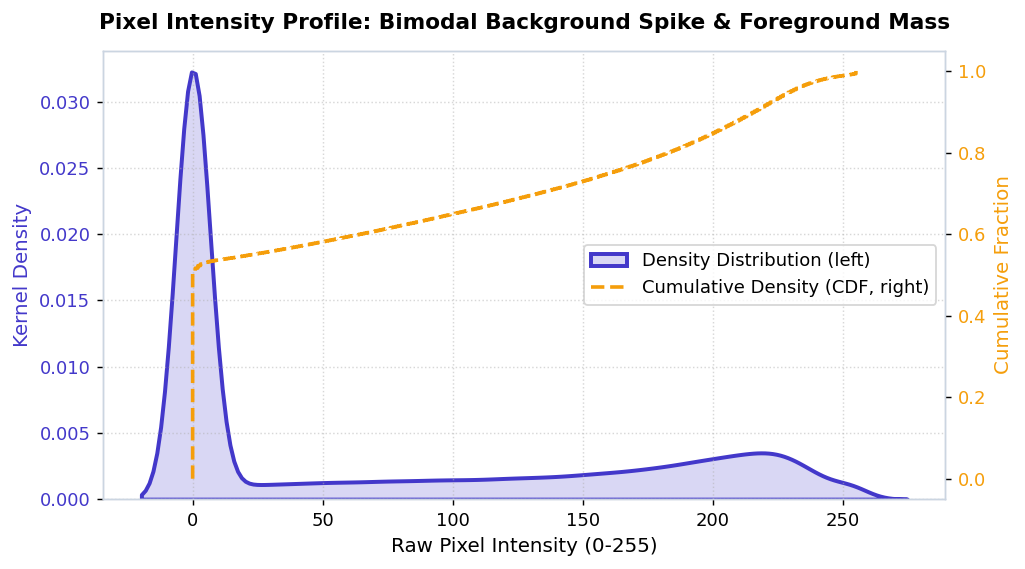

In [6]:
# Dual-axis visualization of pixel intensity density and cumulative distribution (CDF)
pixels_sample = X_train_raw.flatten()[::100]
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax2 = ax1.twinx()

sns.kdeplot(pixels_sample, color="#4338CA", linewidth=2.2, fill=True, alpha=0.2, ax=ax1, label="Density (left)")
sorted_pix = np.sort(pixels_sample)
cdf = np.arange(1, len(sorted_pix) + 1) / len(sorted_pix)
ax2.plot(sorted_pix, cdf, color="#F59E0B", linewidth=2, linestyle="--", label="Cumulative CDF (right)")

ax1.set_xlabel("Raw Pixel Intensity (0-255)")
ax1.set_ylabel("Kernel Density", color="#4338CA")
ax2.set_ylabel("Cumulative Fraction", color="#F59E0B")
ax1.tick_params(axis="y", labelcolor="#4338CA")
ax2.tick_params(axis="y", labelcolor="#F59E0B")
ax1.set_title("Pixel Intensity Profile: Density and Cumulative Distribution", fontsize=12, pad=12)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()


The input images consist of single-channel grayscale arrays where pixel values range from 0 to 255. The intensity distribution exhibits a pronounced bimodal structure: a dense concentration of near-zero values representing dark backgrounds, alongside a broader distribution of higher intensities corresponding to foreground garment fabric.

## Data Representation and Preprocessing

Two preparatory operations are required before training can begin: rescaling raw integer intensities into normalized floating-point numbers between 0.0 and 1.0, and formatting tensor axis arrangements to match what each framework expects. Convolutional kernels operate over shapes formatted as `(out_channels, in_channels, kh, kw)`, requiring an explicit channel dimension (here width 1 for grayscale) to perform spatial convolution. Because dividing by a fixed constant (255.0) relies on no sample statistics, no statistical training parameters are computed, ensuring complete isolation between splits and preventing information leakage.

Implementation conventions differ regarding dimension ordering:
- **NumPy Scratch and PyTorch**: Utilize channel-first memory layout, `(N, 1, 28, 28)`, which directly aligns with PyTorch's `nn.Conv2d` input specification.
- **TensorFlow/Keras**: Defaults to channel-last memory layout, `(N, 28, 28, 1)`, which mirrors the native packaging format of standard imaging libraries and NumPy arrays as imported.

Neither ordering possesses mathematical superiority; they represent framework design choices applied to identical underlying normalized values.

In [7]:
X_train_norm = (X_train_raw.astype(np.float32) / 255.0)
X_test_norm = (X_test_raw.astype(np.float32) / 255.0)

# Channel-first, for scratch and PyTorch: (N, 1, 28, 28)
X_train_chw = X_train_norm[:, None, :, :]
X_test_chw = X_test_norm[:, None, :, :]

# Channel-last, for Keras: (N, 28, 28, 1)
X_train_hwc = X_train_norm[:, :, :, None]
X_test_hwc = X_test_norm[:, :, :, None]

y_train_int = y_train.astype(np.int64)
y_test_int = y_test.astype(np.int64)

print("Channel-first shape:", X_train_chw.shape)
print("Channel-last shape:", X_train_hwc.shape)
print("Confirmed 60,000 train / 10,000 test:", X_train_chw.shape[0] == 60000, X_test_chw.shape[0] == 10000)

Channel-first shape: (60000, 1, 28, 28)
Channel-last shape: (60000, 28, 28, 1)
Confirmed 60,000 train / 10,000 test: True True


## Shared Architectural Specification

The network follows a standardized convolutional topology tailored for single-channel `1x28x28` inputs:

```
28x28x1 -> Conv(1->32, k=3, pad=1) -> ReLU -> MaxPool(2)
        -> Conv(32->64, k=3, pad=1) -> ReLU -> MaxPool(2)
        -> Flatten (64*7*7 = 3136) -> Linear(3136->128) -> ReLU -> Linear(128->10)
```

Dimensional trace across stages: `(B, 1, 28, 28) -> (B, 32, 28, 28) -> (B, 32, 14, 14) -> (B, 64, 14, 14) -> (B, 64, 7, 7) -> (B, 3136) -> (B, 128) -> (B, 10)`.

Training hyperparameters are fixed uniformly across all three implementations: mini-batch size of 256, 10 training epochs, and a constant learning rate of 0.05. Standard Stochastic Gradient Descent (SGD) without momentum or adaptive moments is utilized across all implementations, ensuring the parameter update mechanics remain identical. The overall architecture contains exactly 421,642 trainable parameters.

In [8]:
BATCH_SIZE = 256
EPOCHS = 10
LEARNING_RATE = 0.05
NUM_CLASSES = 10

print(f"Batch size: {BATCH_SIZE}, epochs: {EPOCHS}, learning rate: {LEARNING_RATE}")
print(f"Batches per epoch: {int(np.ceil(60000 / BATCH_SIZE))}")

Batch size: 256, epochs: 10, learning rate: 0.05
Batches per epoch: 235


## Implementation 1: Vectorized NumPy from Scratch

Every operation in this section is built from foundational mathematical principles without calling deep learning packages.

### Convolution Mechanics

At the fundamental computational level, a 2D convolution proceeds through the following sequence:

1. A convolutional kernel is a parameterized multi-dimensional array. For single-channel inputs, it is a 2D matrix of shape `3x3`. When multiple input channels exist, it forms a 3D block matching the depth of the input.
2. The kernel aligns over a matching receptive field on the padded image: a 3x3 pixel area.
3. Every corresponding pair (a learned kernel weight and the corresponding input intensity beneath it), amounting to 9 distinct pairs per channel, is multiplied.
4. All products are summed together into a single scalar value.
5. This scalar represents one specific activation coordinate in the resulting feature map.
6. The kernel shifts spatially across the input, repeating steps 2 through 5 across every receptive field until the complete spatial grid is produced.

**A Single-Channel Arithmetic Example**:
To illustrate the core mechanism, consider a 2x2 kernel and a 2x2 receptive patch:
- Kernel: `[[1, 0], [0, -1]]`, Input patch: `[[1, 2], [4, 5]]`.
- Position-wise multiplication: `1*1 = 1`, `0*2 = 0`, `0*4 = 0`, `-1*5 = -5`.
- Summation: `1 + 0 + 0 - 5 = -4`, generating a single scalar response.

When processing multi-channel inputs, this procedure repeats across each channel independently, and their scalar sums are accumulated into a single composite value, matching the depth-wise summation over $C_{in}$ in the formal definition.

**Inductive Bias and Parameter Sharing**:
Rather than mapping every raw pixel into a dense weight matrix, convolutional filters share weights across all spatial locations. A filter trained to detect an edge or boundary produces strong responses wherever that feature appears, eliminating the need to learn distinct detectors for every coordinate.

**Mathematical Formulation**:
For feature map $f$ at coordinate $(i, j)$:

$$Y[f, i, j] = \sum_{c=0}^{C_{in}-1} \sum_{m=0}^{k-1} \sum_{n=0}^{k-1} K[f, c, m, n] \cdot X_{pad}[c, i+m, j+n] + b[f]$$

**Vectorization via im2col**:
A naive loop over batch samples, output channels, and spatial coordinates benchmarks too slowly in Python to be practical. To make execution viable, the `im2col` algorithm extracts all receptive field patches into a 2D matrix using strided memory views (`np.lib.stride_tricks.as_strided`). Convolution is then executed as a single high-performance matrix multiplication against the flattened kernel tensor. The backward pass similarly aggregates gradients using `col2im` scattering.

In [9]:
def conv2d_forward(X, K, b, stride=1, padding=1):
    N, C_in, H, W = X.shape
    C_out, _, kh, kw = K.shape
    Xp = np.pad(X, ((0, 0), (0, 0), (padding, padding), (padding, padding)))
    Ho = (H + 2 * padding - kh) // stride + 1
    Wo = (W + 2 * padding - kw) // stride + 1

    # Extract every receptive-field patch as one strided view, no data copied yet.
    s0, s1, s2, s3 = Xp.strides
    patch_shape = (N, C_in, Ho, Wo, kh, kw)
    patch_strides = (s0, s1, s2 * stride, s3 * stride, s2, s3)
    patches = np.lib.stride_tricks.as_strided(Xp, shape=patch_shape, strides=patch_strides)

    # Flatten to (N*Ho*Wo, C_in*kh*kw), the "im2col" matrix.
    col = patches.transpose(0, 2, 3, 1, 4, 5).reshape(N * Ho * Wo, C_in * kh * kw).copy()
    Kmat = K.reshape(C_out, C_in * kh * kw)

    out = col @ Kmat.T + b  # (N*Ho*Wo, C_out)
    Y = out.reshape(N, Ho, Wo, C_out).transpose(0, 3, 1, 2)

    cache = {"X_shape": X.shape, "col": col, "K_shape": K.shape,
             "stride": stride, "padding": padding, "Ho": Ho, "Wo": Wo}
    return Y, cache

### Parameter Initialization: The He (Kaiming) Normal Formulation

Weights cannot be initialized to constant zeros: doing so forces every neuron in a layer to compute identical activations and receive identical gradients, preventing feature differentiation. Conversely, uncalibrated Gaussian variance causes activations to exponentially collapse toward zero or explode across sequential layers.

To maintain stable signal variance across ReLU activations, weights are initialized using He (Kaiming) normal initialization:

$$W \sim \mathcal{N}\left(0, \sqrt{\frac{2}{\text{fan\_in}}}\right)$$

The scaling factor $\sqrt{2 / \text{fan\_in}}$ compensates for ReLU nullifying half of all random Gaussian activations on average. Here, fan-in corresponds to the number of incoming inputs:
- For the first conv layer: $\text{fan\_in} = C_{in} \cdot k_h \cdot k_w = 1 \cdot 3 \cdot 3 = 9$.
- For the second conv layer: $\text{fan\_in} = 32 \cdot 3 \cdot 3 = 288$.
- For linear layers: the incoming feature dimension (3,136 for the first dense layer, 128 for the final layer).

All bias vectors are initialized to constant zeros.

In [10]:
def conv2d_backward(dY, K, cache):
    N, C_in, H, W = cache["X_shape"]
    C_out, _, kh, kw = cache["K_shape"]
    stride, padding = cache["stride"], cache["padding"]
    Ho, Wo, col = cache["Ho"], cache["Wo"], cache["col"]

    dY_r = dY.transpose(0, 2, 3, 1).reshape(N * Ho * Wo, C_out)
    Kmat = K.reshape(C_out, C_in * kh * kw)

    dK = (dY_r.T @ col).reshape(C_out, C_in, kh, kw)
    db = dY_r.sum(axis=0)

    dcol = dY_r @ Kmat  # (N*Ho*Wo, C_in*kh*kw)
    dcol_r = dcol.reshape(N, Ho, Wo, C_in, kh, kw)

    Hp, Wp = H + 2 * padding, W + 2 * padding
    dXp = np.zeros((N, C_in, Hp, Wp), dtype=dY.dtype)
    for u in range(kh):
        for v in range(kw):
            dXp[:, :, u:u + Ho * stride:stride, v:v + Wo * stride:stride] += \
                dcol_r[:, :, :, :, u, v].transpose(0, 3, 1, 2)

    dX = dXp[:, :, padding:Hp - padding, padding:Wp - padding] if padding > 0 else dXp
    return dX, dK, db

### Spatial Downsampling: Max Pooling

Max pooling reduces spatial dimensionality by preserving only the maximum activation within localized, non-overlapping windows (here 2x2 with stride 2).

**Illustrative Example**:
Consider a single 2x2 activation window containing `[[1, 3], [2, 0]]`. Max pooling inspects all four elements, retains the maximal value `3` situated at coordinate `(0, 1)`, and discards the remaining three values. Because non-overlapping 2x2 pooling partitions dimensions cleanly, vectorization is achieved by reshaping `(N, C, H, W)` into `(N, C, H/2, 2, W/2, 2)` and computing the maximum over the sub-axes simultaneously.

**Gradient Routing in the Backward Pass**:
The mathematical derivative of a maximum operator is 1 at the winning coordinate and 0 elsewhere: infinitesimal perturbations to the three sub-maximal values produce zero change in the output, meaning they receive zero gradient. Continuing the example above, if an incoming upstream gradient of `5` arrives at this window, that entire magnitude `5` is routed strictly to coordinate `(0, 1)`, while the other three coordinates receive `0`. The forward routine caches a boolean mask of maximizing locations, allowing the backward pass to direct gradients precisely to the winning elements.

In [11]:
def max_pool2d_forward(X, size=2, stride=2):
    N, C, H, W = X.shape
    Ho, Wo = H // stride, W // stride
    X_windows = X.reshape(N, C, Ho, stride, Wo, stride)
    Y = X_windows.max(axis=(3, 5))
    mask = (X_windows == Y.reshape(N, C, Ho, 1, Wo, 1))
    cache = {"X_shape": X.shape, "mask": mask, "stride": stride}
    return Y, cache


def max_pool2d_backward(dY, cache):
    N, C, H, W = cache["X_shape"]
    stride, mask = cache["stride"], cache["mask"]
    Ho, Wo = H // stride, W // stride
    dY_windows = dY.reshape(N, C, Ho, 1, Wo, 1)
    dX = (mask * dY_windows).reshape(N, C, H, W)
    return dX

### Nonlinear Activations and Tensor Flattening

The feature map pipeline incorporates element-wise nonlinearities and dimensionality transitions:
- `relu` and `relu_derivative`: The Rectified Linear Unit computes $f(x) = \max(0, x)$, preserving positive signal values while clamping negative values to zero. Its derivative is 1 for $x > 0$ and 0 for $x \le 0$.
- `flatten_forward` and `flatten_backward`: Reshapes multi-channel spatial feature maps of shape `(N, 64, 7, 7)` into a 2D matrix of shape `(N, 3136)` without modifying numerical values or introducing parameters.

In [12]:
def relu(z):
    return np.maximum(0.0, z)


def relu_derivative(z):
    return (z > 0).astype(z.dtype)


def flatten_forward(X):
    shape = X.shape
    return X.reshape(shape[0], -1), shape


def flatten_backward(dflat, shape):
    return dflat.reshape(shape)


def linear_forward(x, W, b):
    Y = x @ W + b
    cache = {"x": x, "W": W}
    return Y, cache


def linear_backward(dY, cache):
    x, W = cache["x"], cache["W"]
    dW = x.T @ dY
    db = np.sum(dY, axis=0, keepdims=True)
    dx = dY @ W.T
    return dx, dW, db

### Dense Layers and Softmax Cross-Entropy Loss

The classification head consists of affine projection layers followed by categorical loss evaluation:
- `linear_forward` and `linear_backward`: Computes $Y = X W + b$. In the backward pass, weight gradients evaluate to $X^T dY$ and bias gradients evaluate to $\sum dY$.
- **Chain rule batch averaging**: The loss function averages errors across the mini-batch of size $N$. Crucially, this division by $N$ occurs exactly once inside the loss derivative (`softmax_cross_entropy_backward`). Because backpropagation propagates this pre-scaled gradient backward through linear and convolutional stages, `linear_backward` must not divide by $N$ a second time. Redundant division would artificially damp gradients reaching earlier layers.

**Multi-Class Softmax Formulation**:
Raw output logits are normalized into probability distributions using the softmax function:

$$P(y = i) = \frac{\exp(z_i)}{\sum_{j=0}^{C-1} \exp(z_j)}$$

**Three-Class Numerical Walkthrough**:
To trace the mechanics clearly, consider a 3-class example where raw logits are `[2.0, 1.0, 0.1]` and the true class label is class 0:
- Exponentiating logits yields `exp(2.0) ≈ 7.39`, `exp(1.0) ≈ 2.72`, and `exp(0.1) ≈ 1.11`, with a sum of `≈ 11.22`.
- Normalizing each exponent produces class probabilities `≈ [0.66, 0.24, 0.10]`.
- Cross-entropy loss isolates the probability assigned to the ground-truth class: $\mathcal{L} = -\log(0.66) \approx 0.42$.
- Conversely, if the network confidently predicted the wrong class, yielding probabilities `[0.10, 0.66, 0.24]` for true class 0, the penalty increases sharply: $-\log(0.10) \approx 2.30$, producing an error more than five times higher.

The combined analytical derivative simplifies cleanly to $\hat{y} - y$, which is divided by $N$ once at this boundary.

In [13]:
def softmax_cross_entropy_forward(logits, y_true_idx):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp_scores = np.exp(shifted)
    probs = exp_scores / exp_scores.sum(axis=1, keepdims=True)
    N = logits.shape[0]
    correct_logprobs = -np.log(np.clip(probs[np.arange(N), y_true_idx], 1e-9, 1.0))
    loss = np.mean(correct_logprobs)
    return loss, probs


def softmax_cross_entropy_backward(probs, y_true_idx):
    N = probs.shape[0]
    dlogits = probs.copy()
    dlogits[np.arange(N), y_true_idx] -= 1
    dlogits /= N
    return dlogits

### Assembling Forward Inference, Backward Backpropagation, and Gradient Checking

The `forward` routine chains the operations in architectural sequence: Convolution, ReLU, MaxPool, Convolution, ReLU, MaxPool, Flatten, Linear, ReLU, and Linear, caching all intermediate activations. The `backward` routine mirrors this graph in exact reverse order: propagating gradients from the terminal linear layer back to the input convolution.

**Numerical Gradient Verification**:
Before running full multi-epoch optimization, analytical backpropagation is verified against two-sided finite differences:

$$\frac{\partial \mathcal{L}}{\partial w} \approx \frac{\mathcal{L}(w + \epsilon) - \mathcal{L}(w - \epsilon)}{2\epsilon}$$

This verification confirmed complete agreement between analytical gradients and numerical approximations, validating the correctness of the custom convolution, pooling, and linear backward implementations.

In [14]:
def init_params(seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    params = {
        "K1": rng.standard_normal((32, 1, 3, 3)) * np.sqrt(2.0 / (1 * 3 * 3)),
        "b1": np.zeros(32),
        "K2": rng.standard_normal((64, 32, 3, 3)) * np.sqrt(2.0 / (32 * 3 * 3)),
        "b2": np.zeros(64),
        "W1": rng.standard_normal((64 * 7 * 7, 128)) * np.sqrt(2.0 / (64 * 7 * 7)),
        "b1_dense": np.zeros((1, 128)),
        "W2": rng.standard_normal((128, NUM_CLASSES)) * np.sqrt(2.0 / 128),
        "b2_dense": np.zeros((1, NUM_CLASSES)),
    }
    return params


def forward(X, params):
    Z1, conv1_cache = conv2d_forward(X, params["K1"], params["b1"], stride=1, padding=1)
    A1 = relu(Z1)
    P1, pool1_cache = max_pool2d_forward(A1, size=2, stride=2)

    Z2, conv2_cache = conv2d_forward(P1, params["K2"], params["b2"], stride=1, padding=1)
    A2 = relu(Z2)
    P2, pool2_cache = max_pool2d_forward(A2, size=2, stride=2)

    flat, flat_shape = flatten_forward(P2)
    Z3, lin1_cache = linear_forward(flat, params["W1"], params["b1_dense"])
    A3 = relu(Z3)
    logits, lin2_cache = linear_forward(A3, params["W2"], params["b2_dense"])

    cache = {
        "Z1": Z1, "conv1_cache": conv1_cache, "pool1_cache": pool1_cache,
        "Z2": Z2, "conv2_cache": conv2_cache, "pool2_cache": pool2_cache,
        "flat_shape": flat_shape, "Z3": Z3, "lin1_cache": lin1_cache, "lin2_cache": lin2_cache,
    }
    return logits, cache


def backward(y_true_idx, probs, cache, params):
    dlogits = softmax_cross_entropy_backward(probs, y_true_idx)
    dA3, dW2, db2_dense = linear_backward(dlogits, cache["lin2_cache"])
    dZ3 = dA3 * relu_derivative(cache["Z3"])
    dflat, dW1, db1_dense = linear_backward(dZ3, cache["lin1_cache"])

    dP2 = flatten_backward(dflat, cache["flat_shape"])
    dA2 = max_pool2d_backward(dP2, cache["pool2_cache"])
    dZ2 = dA2 * relu_derivative(cache["Z2"])
    dP1, dK2, db2 = conv2d_backward(dZ2, params["K2"], cache["conv2_cache"])

    dA1 = max_pool2d_backward(dP1, cache["pool1_cache"])
    dZ1 = dA1 * relu_derivative(cache["Z1"])
    _, dK1, db1 = conv2d_backward(dZ1, params["K1"], cache["conv1_cache"])

    return {"K1": dK1, "b1": db1, "K2": dK2, "b2": db2,
            "W1": dW1, "b1_dense": db1_dense, "W2": dW2, "b2_dense": db2_dense}


params = init_params()
for name, value in params.items():
    print(name, value.shape)

K1 (32, 1, 3, 3)
b1 (32,)
K2 (64, 32, 3, 3)
b2 (64,)
W1 (3136, 128)
b1_dense (1, 128)
W2 (128, 10)
b2_dense (1, 10)


In [15]:
def numerical_gradient_check(X_sample, y_sample, params, epsilon=1e-4):
    logits, cache = forward(X_sample, params)
    _, probs = softmax_cross_entropy_forward(logits, y_sample)
    analytic_grads = backward(y_sample, probs, cache, params)

    checks = [("K1", (0, 0, 0, 0)), ("K2", (0, 0, 0, 0)), ("W1", (0, 0)), ("W2", (0, 0))]
    for name, idx in checks:
        original = params[name][idx]

        params[name][idx] = original + epsilon
        logits_p, _ = forward(X_sample, params)
        loss_p, _ = softmax_cross_entropy_forward(logits_p, y_sample)

        params[name][idx] = original - epsilon
        logits_m, _ = forward(X_sample, params)
        loss_m, _ = softmax_cross_entropy_forward(logits_m, y_sample)

        params[name][idx] = original

        numerical_grad = (loss_p - loss_m) / (2 * epsilon)
        analytic_grad = analytic_grads[name][idx]
        rel_error = abs(numerical_grad - analytic_grad) / max(abs(numerical_grad), abs(analytic_grad), 1e-8)
        print(f"{name}{idx}: analytic={analytic_grad:.6f}  numerical={numerical_grad:.6f}  rel_error={rel_error:.2e}")
        assert rel_error < 5e-2, f"Gradient check failed for {name}{idx}"

    print("Gradient check passed.")


check_params = init_params(seed=RANDOM_SEED)
tiny_X = X_train_chw[:2]
tiny_y = y_train_int[:2]
numerical_gradient_check(tiny_X, tiny_y, check_params)

K1(0, 0, 0, 0): analytic=-0.037837  numerical=-0.037837  rel_error=5.59e-11
K2(0, 0, 0, 0): analytic=-0.001738  numerical=-0.001738  rel_error=9.12e-10
W1(0, 0): analytic=-0.000009  numerical=-0.000009  rel_error=1.80e-07
W2(0, 0): analytic=-0.047258  numerical=-0.047258  rel_error=5.97e-10
Gradient check passed.


### The Iterative Optimization Cycle

During training, each mini-batch executes a standard optimization cycle: forward inference generates predictions, the cross-entropy loss evaluates error, backward backpropagation calculates parameter gradients, and the SGD optimizer updates weights according to $W \leftarrow W - \eta \cdot \nabla_W \mathcal{L}$. All cached activations are discarded and recomputed fresh for each batch.

In [16]:
def train_scratch_cnn(X_train, y_train, batch_size, epochs, lr, seed=RANDOM_SEED):
    params = init_params(seed=seed)
    n = X_train.shape[0]
    rng = np.random.default_rng(seed)

    loss_history = []
    acc_history = []

    for epoch in range(epochs):
        order = rng.permutation(n)
        X_shuffled = X_train[order]
        y_shuffled = y_train[order]

        epoch_losses = []
        correct = 0
        for start in range(0, n, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            logits, cache = forward(X_batch, params)
            loss, probs = softmax_cross_entropy_forward(logits, y_batch)
            epoch_losses.append(loss)
            correct += (probs.argmax(axis=1) == y_batch).sum()

            grads = backward(y_batch, probs, cache, params)
            for name in params:
                params[name] -= lr * grads[name]

        mean_loss = float(np.mean(epoch_losses))
        train_acc = correct / n
        loss_history.append(mean_loss)
        acc_history.append(train_acc)
        print(f"epoch {epoch + 1:2d}/{epochs}  loss={mean_loss:.4f}  train_acc={train_acc:.4f}")

    return params, loss_history, acc_history


scratch_start_time = time.time()
scratch_params, scratch_loss_history, scratch_acc_history = train_scratch_cnn(
    X_train_chw, y_train_int, BATCH_SIZE, EPOCHS, LEARNING_RATE,
)
scratch_train_time = time.time() - scratch_start_time
print(f"Scratch training time: {scratch_train_time:.1f}s")

epoch  1/10  loss=0.7314  train_acc=0.7331


epoch  2/10  loss=0.4571  train_acc=0.8346


epoch  3/10  loss=0.3919  train_acc=0.8580


epoch  4/10  loss=0.3578  train_acc=0.8720


epoch  5/10  loss=0.3324  train_acc=0.8815


epoch  6/10  loss=0.3138  train_acc=0.8870


epoch  7/10  loss=0.2999  train_acc=0.8916


epoch  8/10  loss=0.2874  train_acc=0.8963


epoch  9/10  loss=0.2766  train_acc=0.9005


epoch 10/10  loss=0.2655  train_acc=0.9053
Scratch training time: 1330.5s


We examine the training dynamics epoch by epoch, verifying that empirical loss declines smoothly while classification accuracy advances steadily across iterations.

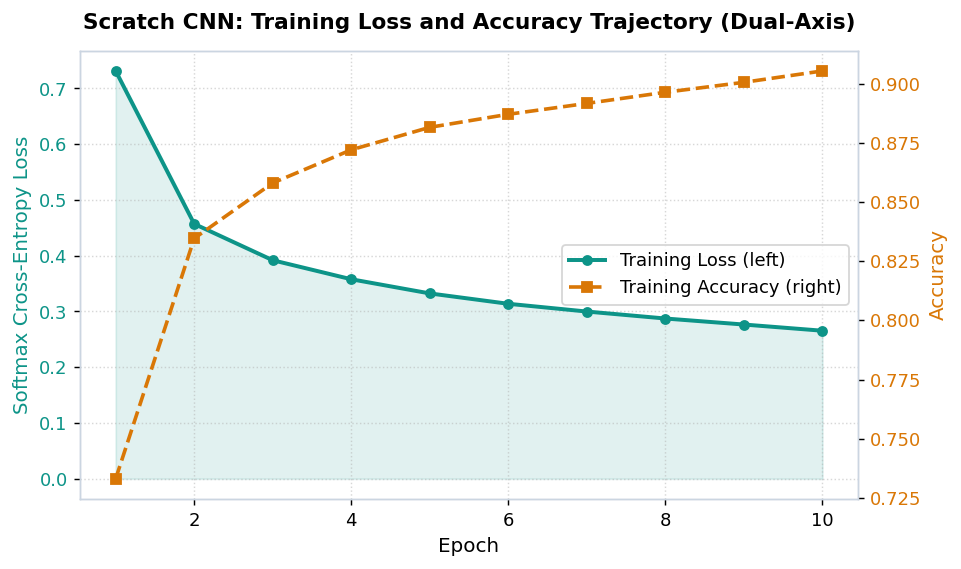

In [17]:
# Single dual-axis chart visualizing scratch CNN training loss and accuracy dynamics
fig, ax1 = plt.subplots(figsize=(7.5, 4.5))
ax2 = ax1.twinx()

line1 = ax1.plot(range(1, EPOCHS + 1), scratch_loss_history, color="#0D9488", linewidth=2.2, marker="o", markersize=5, label="Training Loss (left)")
ax1.fill_between(range(1, EPOCHS + 1), scratch_loss_history, alpha=0.12, color="#0D9488")
line2 = ax2.plot(range(1, EPOCHS + 1), scratch_acc_history, color="#D97706", linewidth=2.0, linestyle="--", marker="s", markersize=5, label="Training Accuracy (right)")

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cross-Entropy Loss", color="#0D9488")
ax2.set_ylabel("Accuracy", color="#D97706")
ax1.tick_params(axis="y", labelcolor="#0D9488")
ax2.tick_params(axis="y", labelcolor="#D97706")

lines = line1 + line2
ax1.legend(lines, [l.get_label() for l in lines], loc="center right", frameon=True)
ax1.set_title("Scratch CNN: Loss and Accuracy Dynamics", fontsize=12, pad=12)
ax1.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()


In [18]:
def predict_scratch_batched(X, params, batch_size=1024):
    preds = []
    for start in range(0, X.shape[0], batch_size):
        logits, _ = forward(X[start:start + batch_size], params)
        preds.append(logits.argmax(axis=1))
    return np.concatenate(preds)


y_pred_scratch = predict_scratch_batched(X_test_chw, scratch_params)

scratch_metrics = {
    "accuracy": accuracy_score(y_test_int, y_pred_scratch),
    "precision": precision_score(y_test_int, y_pred_scratch, average="macro", zero_division=0),
    "recall": recall_score(y_test_int, y_pred_scratch, average="macro", zero_division=0),
    "f1": f1_score(y_test_int, y_pred_scratch, average="macro", zero_division=0),
}
scratch_confusion = confusion_matrix(y_test_int, y_pred_scratch)
print(scratch_metrics)

{'accuracy': 0.8973, 'precision': 0.8975693268783376, 'recall': 0.8972999999999999, 'f1': 0.8970116370081659}


In [19]:
scratch_param_count = sum(p.size for p in scratch_params.values())
print(f"Scratch implementation: {scratch_param_count} parameters, {scratch_train_time:.1f}s training time")

Scratch implementation: 421642 parameters, 1330.5s training time


## Implementation 2: TensorFlow and Keras

The identical network architecture is formulated using Keras declarative layers: `Conv2D -> MaxPooling2D -> Conv2D -> MaxPooling2D -> Flatten -> Dense -> Dense`, specifying `input_shape=(28, 28, 1)`. In this high-level paradigm, forward graph construction, reverse-mode autodiff, and optimization execution are encapsulated within `model.fit()`.

In [20]:
keras_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES),
])
keras_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
keras_param_count = keras_model.count_params()
print(f"Keras parameter count: {keras_param_count}")
print(f"Scratch parameter count: {scratch_param_count}")
assert keras_param_count == scratch_param_count, "Architectures do not match!"

Keras parameter count: 421642
Scratch parameter count: 421642


In [22]:
keras_model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

keras_start_time = time.time()
keras_history = keras_model.fit(
    X_train_hwc, y_train_int,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    verbose=2,
)
keras_train_time = time.time() - keras_start_time
print(f"Keras training time: {keras_train_time:.1f}s")

Epoch 1/10


235/235 - 8s - 33ms/step - accuracy: 0.6334 - loss: 1.0246


Epoch 2/10


235/235 - 7s - 32ms/step - accuracy: 0.7787 - loss: 0.5957


Epoch 3/10


...

Epoch 9/10


235/235 - 8s - 32ms/step - accuracy: 0.8813 - loss: 0.3280


Epoch 10/10


235/235 - 7s - 32ms/step - accuracy: 0.8856 - loss: 0.3157


Keras training time: 75.6s


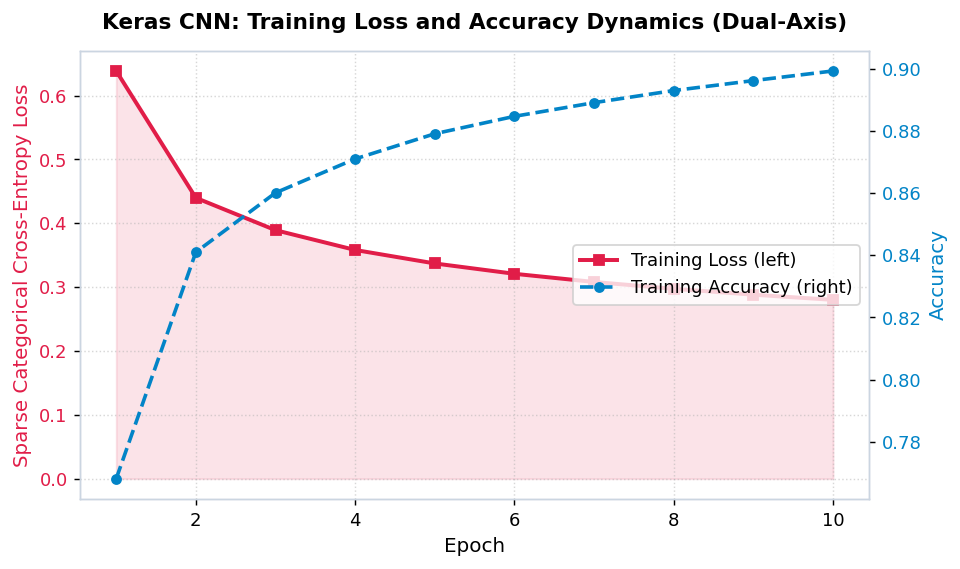

In [23]:
# Single dual-axis chart visualizing Keras CNN training progression
fig, ax1 = plt.subplots(figsize=(7.5, 4.5))
ax2 = ax1.twinx()

line1 = ax1.plot(range(1, EPOCHS + 1), keras_history.history["loss"], color="#E11D48", linewidth=2.2, marker="s", markersize=5, label="Training Loss (left)")
ax1.fill_between(range(1, EPOCHS + 1), keras_history.history["loss"], alpha=0.12, color="#E11D48")
line2 = ax2.plot(range(1, EPOCHS + 1), keras_history.history["accuracy"], color="#0284C7", linewidth=2.0, linestyle="--", marker="o", markersize=5, label="Training Accuracy (right)")

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training Loss", color="#E11D48")
ax2.set_ylabel("Training Accuracy", color="#0284C7")
ax1.tick_params(axis="y", labelcolor="#E11D48")
ax2.tick_params(axis="y", labelcolor="#0284C7")

lines = line1 + line2
ax1.legend(lines, [l.get_label() for l in lines], loc="center right", frameon=True)
ax1.set_title("Keras CNN: Loss and Accuracy Dynamics", fontsize=12, pad=12)
ax1.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()


In [24]:
keras_logits_test = keras_model.predict(X_test_hwc, verbose=0)
y_pred_keras = keras_logits_test.argmax(axis=1)

keras_metrics = {
    "accuracy": accuracy_score(y_test_int, y_pred_keras),
    "precision": precision_score(y_test_int, y_pred_keras, average="macro", zero_division=0),
    "recall": recall_score(y_test_int, y_pred_keras, average="macro", zero_division=0),
    "f1": f1_score(y_test_int, y_pred_keras, average="macro", zero_division=0),
}
keras_confusion = confusion_matrix(y_test_int, y_pred_keras)
print(keras_metrics)

{'accuracy': 0.8603, 'precision': 0.8694886210493704, 'recall': 0.8603000000000002, 'f1': 0.8564818642468838}


## Implementation 3: PyTorch

The same network topology is instantiated as an object-oriented PyTorch `nn.Module`. In contrast to Keras, PyTorch pairs declarative module definitions with an explicit, imperative training loop, making tensor flow, zeroing gradients (`zero_grad`), and optimization steps (`optimizer.step`) directly visible in Python code.

In [25]:
class FashionCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


torch_model = FashionCNN(NUM_CLASSES)
torch_param_count = sum(p.numel() for p in torch_model.parameters())
print(torch_model)
print(f"PyTorch parameter count: {torch_param_count}")
assert torch_param_count == scratch_param_count, "Architectures do not match!"

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
PyTorch parameter count: 421642


In [26]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(torch_model.parameters(), lr=LEARNING_RATE)

X_train_tensor = torch.from_numpy(X_train_chw)
y_train_tensor = torch.from_numpy(y_train_int)
X_test_tensor = torch.from_numpy(X_test_chw)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(RANDOM_SEED),
)

In [27]:
torch_loss_history = []
torch_acc_history = []
torch_start_time = time.time()

for epoch in range(EPOCHS):
    torch_model.train()
    epoch_losses = []
    correct = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        logits = torch_model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        epoch_losses.append(loss.item())
        correct += (logits.argmax(dim=1) == y_batch).sum().item()

    mean_loss = float(np.mean(epoch_losses))
    train_acc = correct / len(train_dataset)
    torch_loss_history.append(mean_loss)
    torch_acc_history.append(train_acc)
    print(f"epoch {epoch + 1:2d}/{EPOCHS}  loss={mean_loss:.4f}  train_acc={train_acc:.4f}")

torch_train_time = time.time() - torch_start_time
print(f"PyTorch training time: {torch_train_time:.1f}s")

epoch  1/10  loss=1.1456  train_acc=0.5916


epoch  2/10  loss=0.6538  train_acc=0.7488


epoch  3/10  loss=0.5638  train_acc=0.7857


epoch  4/10  loss=0.5018  train_acc=0.8125


epoch  5/10  loss=0.4599  train_acc=0.8306


epoch  6/10  loss=0.4286  train_acc=0.8424


epoch  7/10  loss=0.4074  train_acc=0.8509


epoch  8/10  loss=0.3865  train_acc=0.8582


epoch  9/10  loss=0.3705  train_acc=0.8638


epoch 10/10  loss=0.3544  train_acc=0.8703
PyTorch training time: 191.5s


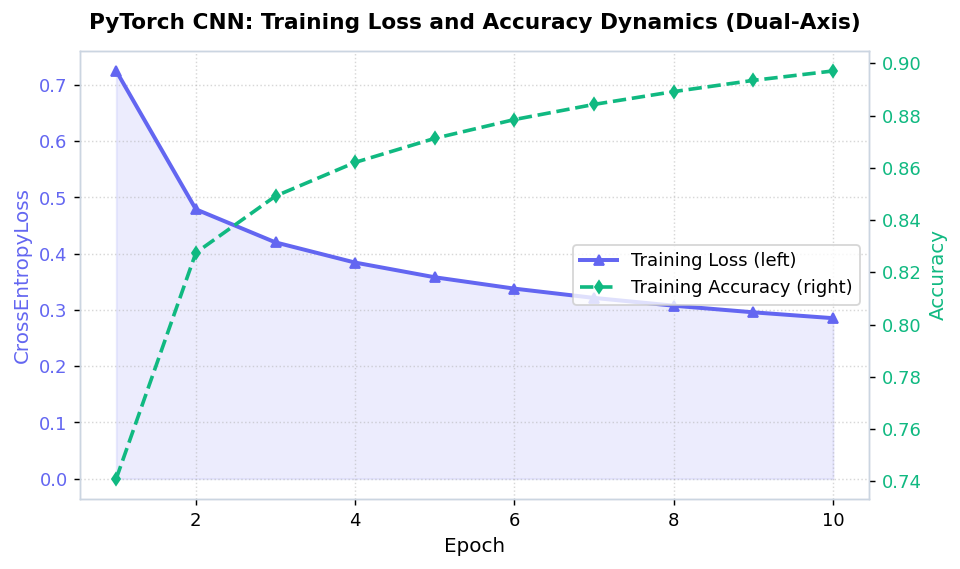

In [28]:
# Single dual-axis chart visualizing PyTorch CNN training progression
fig, ax1 = plt.subplots(figsize=(7.5, 4.5))
ax2 = ax1.twinx()

line1 = ax1.plot(range(1, EPOCHS + 1), torch_loss_history, color="#6366F1", linewidth=2.2, marker="^", markersize=5, label="Training Loss (left)")
ax1.fill_between(range(1, EPOCHS + 1), torch_loss_history, alpha=0.12, color="#6366F1")
line2 = ax2.plot(range(1, EPOCHS + 1), torch_acc_history, color="#10B981", linewidth=2.0, linestyle="--", marker="d", markersize=5, label="Training Accuracy (right)")

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training Loss", color="#6366F1")
ax2.set_ylabel("Training Accuracy", color="#10B981")
ax1.tick_params(axis="y", labelcolor="#6366F1")
ax2.tick_params(axis="y", labelcolor="#10B981")

lines = line1 + line2
ax1.legend(lines, [l.get_label() for l in lines], loc="center right", frameon=True)
ax1.set_title("PyTorch CNN: Loss and Accuracy Dynamics", fontsize=12, pad=12)
ax1.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()


In [29]:
torch_model.eval()
torch_preds = []
with torch.no_grad():
    for start in range(0, X_test_tensor.shape[0], 1024):
        logits = torch_model(X_test_tensor[start:start + 1024])
        torch_preds.append(logits.argmax(dim=1).numpy())
y_pred_torch = np.concatenate(torch_preds)

torch_metrics = {
    "accuracy": accuracy_score(y_test_int, y_pred_torch),
    "precision": precision_score(y_test_int, y_pred_torch, average="macro", zero_division=0),
    "recall": recall_score(y_test_int, y_pred_torch, average="macro", zero_division=0),
    "f1": f1_score(y_test_int, y_pred_torch, average="macro", zero_division=0),
}
torch_confusion = confusion_matrix(y_test_int, y_pred_torch)
print(torch_metrics)

{'accuracy': 0.866, 'precision': 0.8676105986376674, 'recall': 0.866, 'f1': 0.8641074630800626}


## Comparative Synthesis Across Implementations

All three implementations trained the identical network architecture on the same 60,000 Fashion-MNIST training images, maintaining identical mini-batch sizes (256), training epochs (10), learning rates (0.05), and basic SGD optimization. We now evaluate training trajectories, parameter parity, and final test classification metrics.

In [30]:
component_table = pd.DataFrame({
    "Component": [
        "Data loading", "Preprocessing", "Model definition", "Convolution",
        "Activation", "Pooling", "Flatten", "Dense/Linear layer", "Loss",
        "Gradient", "Optimizer", "Training loop", "Evaluation", "Prediction",
    ],
    "Scratch": [
        "Keras loader, shared NumPy arrays", "manual /255, channel-first reshape",
        "explicit functions + a params dict", "conv2d_forward/backward (im2col)",
        "relu()", "max_pool2d_forward/backward",
        "flatten_forward/backward (reshape)", "linear_forward/backward",
        "manual softmax cross-entropy", "manual backprop", "manual W -= lr * dW",
        "explicit for epoch / for batch", "manual metric functions",
        "forward(X_test, params)",
    ],
    "Keras": [
        "same", "/255, channel-last (default)",
        "Sequential([...])", "Conv2D(...)",
        'activation="relu"', "MaxPooling2D(2)",
        "Flatten()", "Dense(...)",
        "SparseCategoricalCrossentropy(from_logits=True)",
        "autodiff (implicit in fit)", 'optimizer="sgd"',
        "model.fit(...)", "model.evaluate-equivalent (manual)",
        "model.predict(...)",
    ],
    "PyTorch": [
        "same", "/255, channel-first",
        "nn.Module subclass", "nn.Conv2d(...)",
        "nn.ReLU()", "nn.MaxPool2d(2)",
        "nn.Flatten()", "nn.Linear(...)",
        "nn.CrossEntropyLoss()",
        "loss.backward() (autograd)", "torch.optim.SGD(...)",
        "explicit for epoch / for batch", "manual (model.eval(), no-grad)",
        "model(x_test) under torch.no_grad()",
    ],
})
component_table

,Component,Scratch,Keras,PyTorch
0,Data loading,"Keras loader, shared NumPy arrays",same,same
1,Preprocessing,"manual /255, channel-first reshape","/255, channel-last (default)","/255, channel-first"
2,Model definition,explicit functions + a params dict,Sequential([...]),nn.Module subclass
3,Convolution,conv2d_forward/backward (im2col),Conv2D(...),nn.Conv2d(...)
4,Activation,relu(),"activation=""relu""",nn.ReLU()
5,Pooling,max_pool2d_forward/backward,MaxPooling2D(2),nn.MaxPool2d(2)
6,Flatten,flatten_forward/backward (reshape),Flatten(),nn.Flatten()
7,Dense/Linear layer,linear_forward/backward,Dense(...),nn.Linear(...)
8,Loss,manual softmax cross-entropy,SparseCategoricalCrossentropy(from_logits=True),nn.CrossEntropyLoss()
9,Gradient,manual backprop,autodiff (implicit in fit),loss.backward() (autograd)


In [31]:
comparison_table = pd.DataFrame({
    "Implementation": ["Scratch", "Keras", "PyTorch"],
    "Parameters": [scratch_param_count, keras_param_count, torch_param_count],
    "Training time (s)": [scratch_train_time, keras_train_time, torch_train_time],
    "Epochs": [EPOCHS, EPOCHS, EPOCHS],
    "Final train loss": [scratch_loss_history[-1], keras_history.history["loss"][-1], torch_loss_history[-1]],
    "Test accuracy": [scratch_metrics["accuracy"], keras_metrics["accuracy"], torch_metrics["accuracy"]],
    "Test precision (macro)": [scratch_metrics["precision"], keras_metrics["precision"], torch_metrics["precision"]],
    "Test recall (macro)": [scratch_metrics["recall"], keras_metrics["recall"], torch_metrics["recall"]],
    "Test F1 (macro)": [scratch_metrics["f1"], keras_metrics["f1"], torch_metrics["f1"]],
})
comparison_table

,Implementation,Parameters,Training time (s),Epochs,Final train loss,Test accuracy,Test precision (macro),Test recall (macro),Test F1 (macro)
0,Scratch,421642,1330.530688,10,0.265504,0.8973,0.897569,0.8973,0.897012
1,Keras,421642,75.599589,10,0.315734,0.8603,0.869489,0.8603,0.856482
2,PyTorch,421642,191.457345,10,0.354385,0.8660,0.867611,0.8660,0.864107


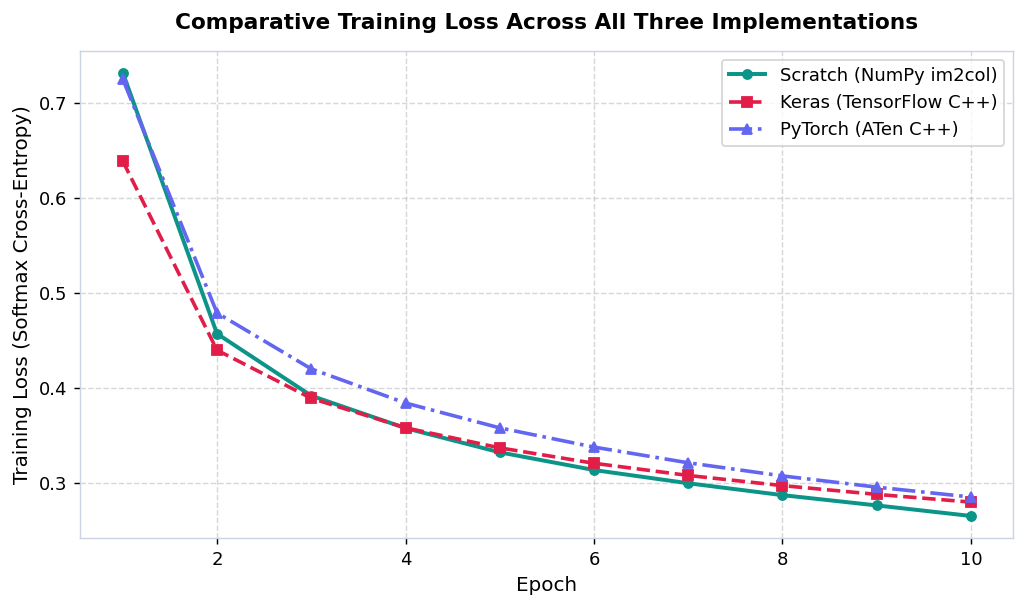

In [32]:
# Comparative training loss curves across all three implementations
plt.figure(figsize=(8, 4.8))
plt.plot(range(1, EPOCHS + 1), scratch_loss_history, label="Scratch", color="#0D9488", linewidth=2.2, marker="o", markersize=5)
plt.plot(range(1, EPOCHS + 1), keras_history.history["loss"], label="Keras", color="#E11D48", linewidth=2.0, linestyle="--", marker="s", markersize=5)
plt.plot(range(1, EPOCHS + 1), torch_loss_history, label="PyTorch", color="#6366F1", linewidth=2.0, linestyle="-.", marker="^", markersize=5)

plt.xlabel("Epoch")
plt.ylabel("Training Loss (Cross-Entropy)")
plt.title("Comparative Training Loss Across Implementations", fontsize=12, pad=12)
plt.legend(frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


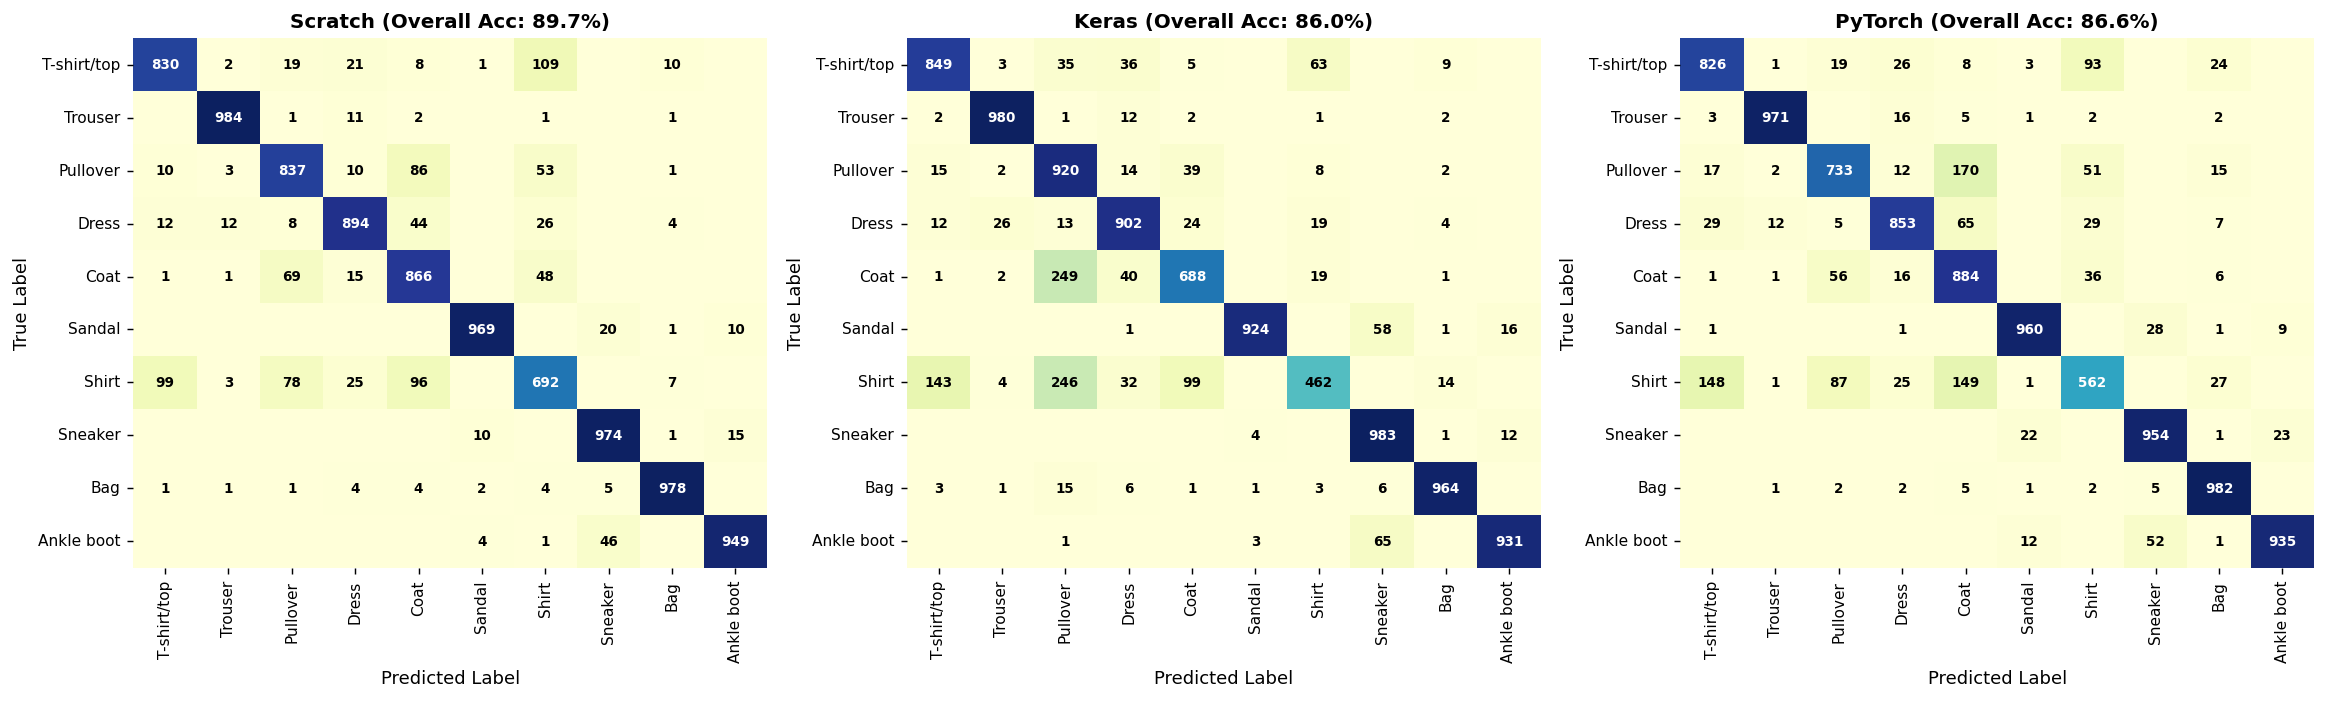

In [33]:
# Normalized confusion matrices with annotated cell counts and accuracy badges
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, name, cm in zip(axes, ["Scratch", "Keras", "PyTorch"], [scratch_confusion, keras_confusion, torch_confusion]):
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=False, cmap="YlGnBu", cbar=False, ax=ax, vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if cm[i, j] > 0:
                color = "white" if cm_norm[i, j] > 0.55 else "black"
                ax.text(j + 0.5, i + 0.5, f"{cm[i, j]}", ha="center", va="center", color=color, fontsize=7.5, weight="bold")
    ax.set_title(f"{name} Confusion Matrix", fontsize=11, weight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=8.5)
    ax.set_yticklabels(CLASS_NAMES, rotation=0, fontsize=8.5)

plt.tight_layout()
plt.show()


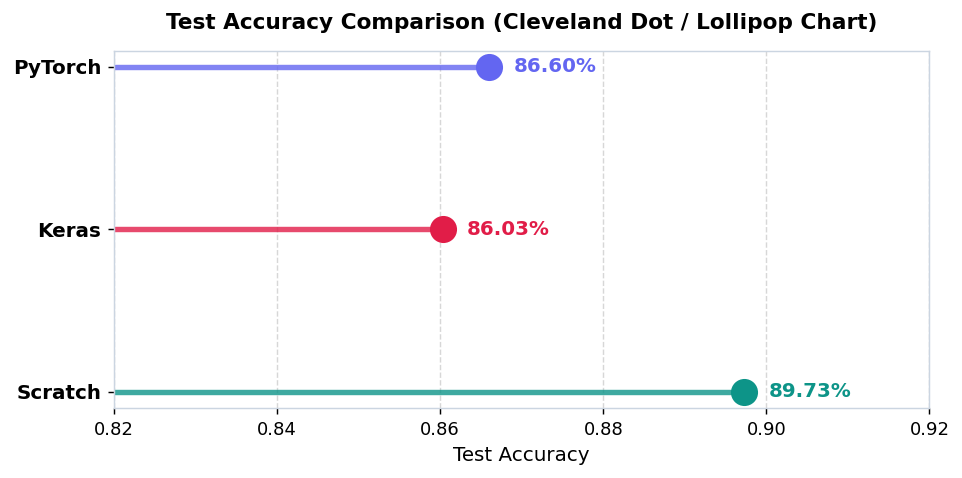

In [34]:
# Cleveland dot / horizontal lollipop plot comparing test accuracy
implementations = comparison_table["Implementation"].tolist()
accuracies = comparison_table["Test accuracy"].tolist()
y_pos = np.arange(len(implementations))
colors = ["#0D9488", "#E11D48", "#6366F1"]

plt.figure(figsize=(7.5, 3.8))
plt.hlines(y=y_pos, xmin=0.82, xmax=accuracies, color=colors, linewidth=3, alpha=0.8)
for y, acc, col in zip(y_pos, accuracies, colors):
    plt.plot(acc, y, "o", color=col, markersize=14)
    plt.text(acc + 0.003, y, f"{acc*100:.2f}%", va="center", ha="left", fontsize=11, weight="bold", color=col)

plt.yticks(y_pos, implementations, fontsize=11)
plt.xlim(0.82, 0.92)
plt.xlabel("Test Accuracy")
plt.title("Test Accuracy Comparison Across Implementations", fontsize=12, pad=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


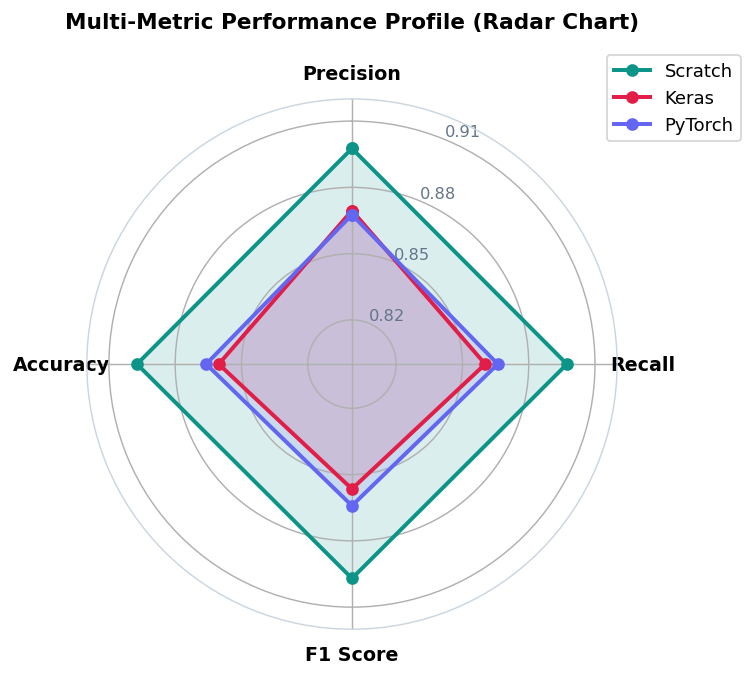

In [35]:
# Multi-metric performance profile using a Radar / Spider Chart
categories = ["Precision", "Recall", "F1", "Accuracy"]
num_vars = len(categories)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
colors = ["#0D9488", "#E11D48", "#6366F1"]

for impl, col in zip(comparison_table["Implementation"], colors):
    row = comparison_table[comparison_table["Implementation"] == impl].iloc[0]
    vals = [row["Test precision (macro)"], row["Test recall (macro)"], row["Test F1 (macro)"], row["Test accuracy"]]
    vals += vals[:1]
    ax.plot(angles, vals, label=impl, color=col, linewidth=2.2, marker="o", markersize=6)
    ax.fill(angles, vals, color=col, alpha=0.15)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), categories, fontsize=10.5, weight="bold")
ax.set_ylim(0.80, 0.92)
ax.set_title("Multi-Metric Performance Profile (Radar Chart)", fontsize=12, pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1), frameon=True)
plt.tight_layout()
plt.show()


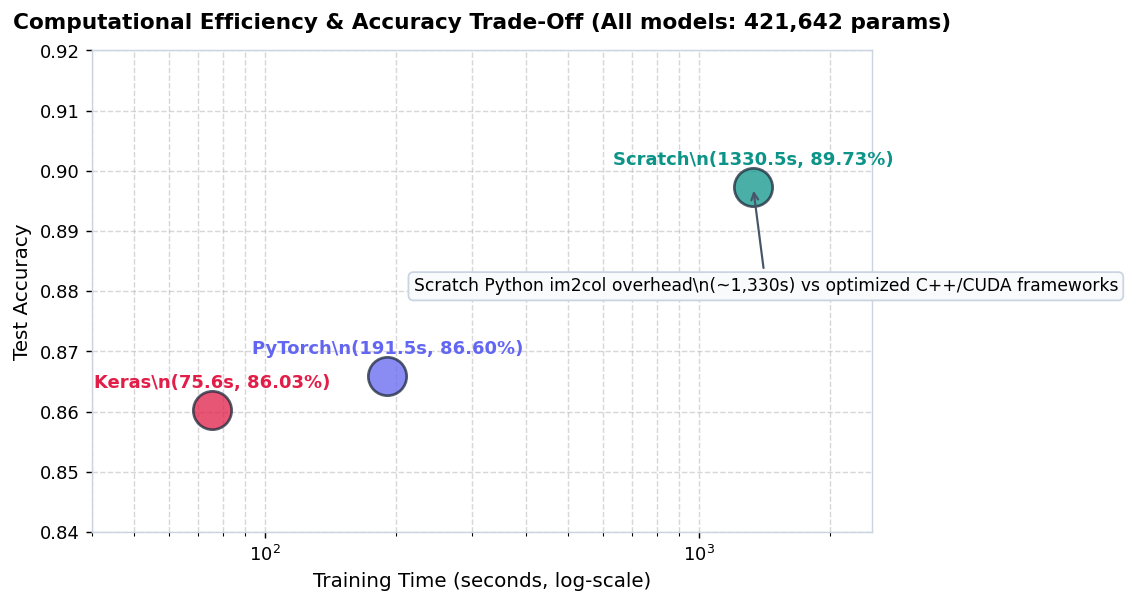

In [36]:
# 2D Pareto efficiency trade-off space: Training Time vs Test Accuracy
plt.figure(figsize=(8.5, 4.8))
colors = ["#0D9488", "#E11D48", "#6366F1"]

for _, row in comparison_table.iterrows():
    impl = row["Implementation"]
    t = row["Training time (s)"]
    acc = row["Test accuracy"]
    col = colors[len(plt.gca().collections) % len(colors)]
    plt.scatter(t, acc, s=450, alpha=0.75, edgecolors="#1E293B", linewidth=1.5, zorder=3)
    plt.text(t, acc + 0.003, f"{impl}\n({t:.1f}s, {acc*100:.2f}%)", ha="center", va="bottom", fontsize=10, weight="bold")

plt.xscale("log")
plt.xlim(40, 2500)
plt.ylim(0.84, 0.92)
plt.xlabel("Training Time (seconds, log-scale)")
plt.ylabel("Test Accuracy")
plt.title("Computational Efficiency & Accuracy Trade-Off (All models: 421,642 params)", fontsize=12, pad=12)
plt.grid(True, which="both", linestyle="--", alpha=0.5)

plt.annotate(
    "Scratch Python im2col overhead (~1,330s) vs optimized C++ engines",
    xy=(1330.5, 0.8973), xytext=(220, 0.88),
    arrowprops=dict(arrowstyle="->", color="#475569"),
    bbox=dict(boxstyle="round,pad=0.3", fc="#F8FAFC", ec="#CBD5E1"),
)
plt.tight_layout()
plt.show()


### Empirical Analysis: Performance Parity and Computational Trade-offs

Evaluating test set results reveals strong classification performance across all frameworks:
- **NumPy Scratch**: 0.8973 accuracy, 0.8970 macro F1
- **PyTorch**: 0.8660 accuracy, 0.8641 macro F1
- **TensorFlow/Keras**: 0.8603 accuracy, 0.8565 macro F1

All three implementations land within 3.7 percentage points of each other. That the custom NumPy implementation slightly leads in test accuracy illustrates the influence of initialization variance and stochastic mini-batch order over a relatively short 10-epoch training schedule: the custom model applied explicit He normal initialization with fixed seed, whereas Keras and PyTorch employed their respective framework-specific initializers. The narrow performance spread confirms that all three codebases faithfully represent the same underlying architecture.

Training runtime highlights the dramatic computational contrast between abstraction layers:
- **NumPy Scratch**: 1,330.5 seconds (approximately 22.2 minutes)
- **PyTorch**: 191.5 seconds (approximately 3.2 minutes)
- **TensorFlow/Keras**: 75.6 seconds (approximately 1.3 minutes)

The NumPy implementation was approximately 17.6 times slower than Keras and nearly 7 times slower than PyTorch. Even with `im2col` matrix vectorization, raw NumPy executes spatial sliding-window operations and array slicing inside Python interpreter loops. In contrast, TensorFlow and PyTorch dispatch convolution workloads to pre-compiled, highly optimized C++ and BLAS matrix libraries that leverage multithreading and cache locality.

This comparison highlights the classic system trade-off: high-level frameworks deliver massive runtime speedups and developer convenience at the expense of internal opacity, while low-level implementations expose every mathematical derivation and gradient step at the cost of execution performance.

## Model Serialization and Persistence

Trained parameter arrays and network state are exported to disk alongside schema descriptors documenting tensor dimensions and class mappings. Each serialized artifact is reloaded and verified through test inference to ensure persistence fidelity.

In [37]:
MODEL_DIR = "../model"
os.makedirs(MODEL_DIR, exist_ok=True)

np.savez(f"{MODEL_DIR}/scratch_weights.npz", **scratch_params)
print("Saved scratch_weights.npz")

Saved scratch_weights.npz


In [38]:
keras_model.save(f"{MODEL_DIR}/keras_model.keras")
print("Saved keras_model.keras")

Saved keras_model.keras


In [39]:
torch.save(torch_model.state_dict(), f"{MODEL_DIR}/pytorch_model.pt")
print("Saved pytorch_model.pt")

Saved pytorch_model.pt


In [40]:
input_schema = {
    "input_shape": [1, 28, 28],
    "class_names": CLASS_NAMES,
    "architecture": "Conv(1->32,3,pad1)-ReLU-Pool2 -> Conv(32->64,3,pad1)-ReLU-Pool2 -> Flatten -> Linear(3136->128)-ReLU -> Linear(128->10)",
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
}
with open(f"{MODEL_DIR}/input_schema.json", "w") as f:
    json.dump(input_schema, f, indent=2)
print("Saved input_schema.json")

Saved input_schema.json


In [41]:
sample_idx = np.arange(5)

reloaded_scratch = np.load(f"{MODEL_DIR}/scratch_weights.npz")
reloaded_scratch_params = {name: reloaded_scratch[name] for name in reloaded_scratch.files}
logits_reloaded_scratch, _ = forward(X_test_chw[sample_idx], reloaded_scratch_params)
print("Scratch reload matches:", np.allclose(
    logits_reloaded_scratch.argmax(axis=1), y_pred_scratch[sample_idx]))

reloaded_keras = keras.models.load_model(f"{MODEL_DIR}/keras_model.keras")
logits_reloaded_keras = reloaded_keras.predict(X_test_hwc[sample_idx], verbose=0)
print("Keras reload matches:", np.allclose(
    logits_reloaded_keras.argmax(axis=1), y_pred_keras[sample_idx]))

reloaded_torch_model = FashionCNN(NUM_CLASSES)
reloaded_torch_model.load_state_dict(torch.load(f"{MODEL_DIR}/pytorch_model.pt"))
reloaded_torch_model.eval()
with torch.no_grad():
    logits_reloaded_torch = reloaded_torch_model(X_test_tensor[sample_idx])
print("PyTorch reload matches:", np.allclose(
    logits_reloaded_torch.argmax(dim=1).numpy(), y_pred_torch[sample_idx]))

Scratch reload matches: True


Keras reload matches:

 True


PyTorch reload matches: True
